# Day 37 — Practice ANSWERS
### What Right Means — evaluation metrics for classification

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

| Part | What it asks you to do | How many |
|---|---|---|
| **A** | Work it out — pen and paper | 8 |
| **B** | Find the mistake in a report | 4 |
| **C** | Write the code yourself | 5 |
| **D** | Challenge | 2 |

### Four questions to keep asking

- What is the **baseline**? What does doing nothing score?
- Of the four boxes, **which one is the expensive one**?
- Who chose the **cut-off**, and what does each mistake cost?
- Is this number a **rate out of the predictions**, or **out of the real cases**?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, fbeta_score,
                             balanced_accuracy_score, matthews_corrcoef,
                             roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score,
                             classification_report)

import warnings
warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (8, 3.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print("ready")

ready


---
# Part A — Work it out

Most of these need nothing but arithmetic. Work them out, then run the cell to check.

### A1 · Fill in the matrix

A spam filter was run on **1,000 emails**. 80 of them were really spam.
It flagged **95** emails, and **60** of those really were spam.

Draw the confusion matrix and work out all four boxes.

In [2]:
total, real_spam, flagged, tp = 1000, 80, 95, 60
fp = flagged - tp
fn = real_spam - tp
tn = total - tp - fp - fn
print(f"                 said legit   said spam")
print(f"actually legit   {tn:>10}   {fp:>9}")
print(f"actually spam    {fn:>10}   {tp:>9}")
print(f"\ncheck: {tn}+{fp}+{fn}+{tp} = {tn+fp+fn+tp}")

                 said legit   said spam
actually legit          885          35
actually spam            20          60

check: 885+35+20+60 = 1000


```
                 said legit   said spam
actually legit          885          35
actually spam            20          60
```

**How each box is found:**

- **tp = 60** — given: it flagged 95 and 60 of them really were spam
- **fp = 95 − 60 = 35** — the rest of what it flagged was wrong
- **fn = 80 − 60 = 20** — the spam it did not flag
- **tn = 1000 − 60 − 35 − 20 = 885** — everything else

The thing to notice: you were given three numbers and the fourth box, **tn = 885**, is by
far the largest. That single box is why accuracy on this problem will look good whatever
the filter does.

### A2 · The four metrics, by hand

From the matrix in A1, work out accuracy, precision, recall and specificity.
Then say what each sentence means in plain English.

In [3]:
tn, fp, fn, tp = 885, 35, 20, 60
print(f"accuracy    = ({tp} + {tn}) / 1000 = {(tp+tn)/1000:.4f}")
print(f"precision   = {tp} / ({tp} + {fp}) = {tp/(tp+fp):.4f}")
print(f"recall      = {tp} / ({tp} + {fn}) = {tp/(tp+fn):.4f}")
print(f"specificity = {tn} / ({tn} + {fp}) = {tn/(tn+fp):.4f}")
print(f"\nF1 = {2*(tp/(tp+fp))*(tp/(tp+fn))/((tp/(tp+fp))+(tp/(tp+fn))):.4f}")
print(f"'never flag anything' would score {920/1000:.4f} on accuracy")

accuracy    = (60 + 885) / 1000 = 0.9450
precision   = 60 / (60 + 35) = 0.6316
recall      = 60 / (60 + 20) = 0.7500
specificity = 885 / (885 + 35) = 0.9620

F1 = 0.6857
'never flag anything' would score 0.9200 on accuracy


```
accuracy    = 0.9450
precision   = 0.6316
recall      = 0.7500
specificity = 0.9620
F1          = 0.6857
```

**In plain English:**

- **accuracy 0.9450** — it gets 945 of every 1,000 emails right. *But a filter that never
  flagged anything would score 0.9200*, so this is a gain of 2.5 points.
- **precision 0.6316** — when it moves an email to the spam folder, it is right about two
  times in three. **One in three things in your spam folder is a real email.**
- **recall 0.7500** — of all the spam actually sent, three quarters got caught. 20 pieces
  landed in the inbox.
- **specificity 0.9620** — 96% of real emails were left alone.

**Which matters here?** For a spam filter, almost everyone would say **precision** —
losing a real email in the spam folder is far worse than seeing one piece of spam in the
inbox. 0.6316 is not good enough to be deployed on anybody's work email.

### A3 · Precision or recall?

For each, say which of the two you would optimise, and in one line why.

1. A model that decides which luggage to open at airport security
2. A model that auto-deletes "obviously fake" job applications before any human sees them
3. A model that flags transactions for a human fraud analyst to review
4. A model that decides, with no human involved, whether to decline a card
5. A model that picks which 50 of 10,000 patients get a free preventive check-up

**1 · Luggage at security — recall.** A missed weapon is catastrophic; an unnecessary bag
search costs three minutes. Accept a great many false alarms.

**2 · Auto-deleting job applications — precision**, overwhelmingly. Each false positive
is a real person silently removed from consideration with no appeal and no human ever
knowing. Honestly, the right answer here is *"do not auto-delete at all"* — rank the
applications instead and have a person work down the list.

**3 · Flagging for a human analyst — recall.** The whole point of the human is to filter
out the false alarms, so the model's job is to not miss things. Precision only needs to
be good enough that the analyst's queue is manageable.

**4 · Auto-declining a card — precision.** There is no human to catch the mistake and the
customer is stranded. Same model as (3), completely different answer, **because of what
happens after the prediction**.

**5 · Choosing 50 patients for a check-up — neither, exactly.** You have a fixed budget of
50, so the question is not "what cut-off" but *"are the top 50 by predicted risk actually
high risk?"* That is **precision at k**, and it is what ranking problems need.

### The pattern

(3) and (4) use the same model on the same data and want opposite things. **The metric
follows the consequence, not the model.**

### A4 · Two models, one decision

| | precision | recall |
|---|---|---|
| **Model A** | 0.90 | 0.30 |
| **Model B** | 0.45 | 0.75 |

1. Work out F1 for each.
2. Which has the higher F1?
3. Now suppose this is a **cancer screen**. Which would you deploy?

In [4]:
for nm, p_, r_ in [("A", 0.90, 0.30), ("B", 0.45, 0.75)]:
    print(f"model {nm}:  F1 = {2*p_*r_/(p_+r_):.4f}   "
          f"F2 = {5*p_*r_/(4*p_+r_):.4f}   plain avg = {(p_+r_)/2:.3f}")

model A:  F1 = 0.4500   F2 = 0.3462   plain avg = 0.600
model B:  F1 = 0.5625   F2 = 0.6618   plain avg = 0.600


```
model A:  F1 = 0.4500   F2 = 0.3462   plain avg = 0.600
model B:  F1 = 0.5625   F2 = 0.6618   plain avg = 0.600
```

**2 · Model B has the higher F1** — 0.5625 against 0.4500.

**3 · For a cancer screen, deploy B — and the F1 is not the reason.**

Model A finds **30%** of the cancers. Seven in ten patients with cancer are told they are
fine. That is not a trade-off you make to gain precision; it is a screening programme
that does not screen.

Model B finds 75%, at the price that fewer than half its referrals turn out to be
cancer — which for a screening test is completely normal, because the next step is a
diagnostic test, not treatment.

**Note the F2 column.** Weighting recall double widens the gap from 0.11 to 0.32. That is
what it looks like to encode "a miss is worse than a false alarm" in a number.

**And note the plain average: 0.600 for both.** It cannot tell these two apart at all.

### A5 · What does AUC 0.80 mean?

Three statements. Which are true?

1. "The model is right 80% of the time."
2. "Pick a random positive and a random negative — there is an 80% chance the positive
   gets the higher score."
3. "At the best cut-off, accuracy is 80%."
4. "The model would still score 0.80 if the positive class were ten times rarer."

**1 · False.** AUC is not an accuracy. A model with AUC 0.80 might be right 99% of the
time or 50% of the time depending on the cut-off and the class balance.

**2 · True.** This *is* the definition of AUC, and Part D asks you to verify it by
counting pairs.

**3 · False.** There is no general relationship between AUC and the accuracy at any
particular cut-off. In the lecture, AUC 0.9141 sat alongside accuracy 0.9583 — and
alongside a recall of 0.2310.

**4 · Roughly true, and this is the important one.** ROC AUC barely moves when the class
balance changes — in the lecture it went 0.9141 → 0.9098 → 0.9322 → 0.8949 as fraud fell
from 4.83% to 0.51%. Over the same range **average precision collapsed from 0.4528 to
0.0740.**

That stability is sometimes a feature (comparing models across datasets) and sometimes
a trap (it hides how bad precision has become).

### A6 · Read a classification report

```
              precision    recall  f1-score   support

     routine     0.9400    0.9700    0.9548      3200
      urgent     0.4800    0.3100    0.3767       290
    critical     0.6700    0.2200    0.3312        50

    accuracy                         0.9140      3540
   macro avg     0.6967    0.5000    0.5542      3540
weighted avg     0.8886    0.9140    0.8972      3540
```

1. How many `critical` cases were there, and how many did the model find?
2. Why is `weighted avg` F1 so much higher than `macro avg`?
3. Which single row would you take to the meeting?

In [5]:
print("critical: support 50, recall 0.22  ->", round(50*0.22), "found,",
      50 - round(50*0.22), "missed")
print("urgent  : support 290, recall 0.31 ->", round(290*0.31), "found,",
      290 - round(290*0.31), "missed")
print()
print("routine is", f"{3200/3540:.1%}", "of all cases")

critical: support 50, recall 0.22  -> 11 found, 39 missed
urgent  : support 290, recall 0.31 -> 90 found, 200 missed

routine is 90.4% of all cases


**1 · There were 50 critical cases and the model found 11 of them.** Recall 0.22 × 50 = 11.
**It missed 39.** For a category called *critical*, on a system presumably built to find
exactly those.

**2 · Because `routine` is 90.4% of the cases and scores 0.9548.**

Weighted averaging multiplies each class's F1 by how common it is, so routine's excellent
score is worth nine tenths of the total. Macro gives all three classes equal say, so
urgent's 0.3767 and critical's 0.3312 pull it down to 0.5542.

**The 0.8972 is not wrong. It is just answering a question nobody cares about** —
"how well does this do on a randomly chosen case?" — when the real question is "how well
does it do on the cases that matter?"

**3 · Take the `critical` row.** 11 of 50.

Everything else on that report, including the 0.9140 accuracy, is a description of how
common routine cases are. The one line that tells you whether the system works is the one
with support 50.

### A7 · Cut-off arithmetic

A model scores 1,000 loan applications. 100 will default.

At a cut-off of **0.3** it flags 250 applications and catches 70 of the defaulters.
At a cut-off of **0.6** it flags 80 applications and catches 40 of the defaulters.

Work out precision and recall at each, and say which you would choose if a default costs
₹50,000 and wrongly refusing a good customer costs ₹3,000.

In [6]:
for t, flagged, caught in [(0.3, 250, 70), (0.6, 80, 40)]:
    fp_ = flagged - caught
    missed = 100 - caught
    cost = 50000*missed + 3000*fp_
    print(f"cut-off {t}:  precision {caught/flagged:.4f}   recall {caught/100:.4f}")
    print(f"             {missed} defaults missed = {50000*missed:>9,}")
    print(f"             {fp_} good customers refused = {3000*fp_:>9,}")
    print(f"             total = {cost:,}\n")
print(f"flag nobody: {50000*100:,}")

cut-off 0.3:  precision 0.2800   recall 0.7000
             30 defaults missed = 1,500,000
             180 good customers refused =   540,000
             total = 2,040,000

cut-off 0.6:  precision 0.5000   recall 0.4000
             60 defaults missed = 3,000,000
             40 good customers refused =   120,000
             total = 3,120,000

flag nobody: 5,000,000


```
cut-off 0.3:  precision 0.2800   recall 0.7000
             30 defaults missed = 1,500,000
             180 good customers refused =   540,000
             total = 2,040,000

cut-off 0.6:  precision 0.5000   recall 0.4000
             60 defaults missed = 3,000,000
             40 good customers refused =   120,000
             total = 3,120,000

flag nobody: 5,000,000
```

**Choose 0.3**, and it is not close — it saves **₹1,080,000** over 0.6.

The reason is the ratio: a default costs **16.7 times** what a wrong refusal costs. When
one mistake is that much more expensive than the other, you accept a lot of the cheap
mistake to avoid the expensive one. 0.3 refuses 180 good customers *and is still far
cheaper*.

**And note that 0.6 has the better precision.** If you had picked the cut-off by
maximising precision — or by any metric that treats the two errors as comparable — you
would have chosen the option that costs a million rupees more.

### A8 · Which metric would you ask for?

Say what you would ask for, in one line each.

1. Your team has built 12 models and wants to shortlist 3 for proper testing.
2. A regulator asks whether your credit model treats two groups of applicants equally.
3. Your manager wants one number for a board slide.
4. You have to decide today whether to switch the fraud system on.

**1 · Twelve models to shortlist — AUC** (or average precision if the class is rare).

You are comparing *rankings*, not choosing a cut-off, and AUC is the measure that does not
depend on one. Fix the cut-off question for the three that survive.

**2 · The regulator — the full confusion matrix, computed separately for each group.**

Not one metric. A model can have identical accuracy for two groups while having very
different recall, and "we miss twice as many good applicants in group B" is exactly the
kind of thing a single number is built to hide. This is the whole field of fairness
metrics, and every one of them is a statement about the four boxes within a subgroup.

**3 · One number for a board slide — give two.** F1 or AUC, **and the baseline**.

A single number with nothing to compare it to is not information. If you are truly
allowed only one, make it something that scores a do-nothing model at zero — F1 or MCC,
never accuracy.

**4 · Deciding today whether to switch it on — expected cost in rupees.**

This is a decision, not a comparison, so the question is not "is the model good" but
"does running it beat not running it". That needs the confusion matrix at your chosen
cut-off and a price for each mistake. No generic metric answers it.

---
# Part B — Find the mistake

Four reports. Every number in them is **arithmetically correct**. Every one is
misleading.

In [7]:
# ---------------------------------------------------------------
# 3,000 hospital discharges. B and C both use `hosp`.
# Can we predict who will be readmitted within 30 days?
# ---------------------------------------------------------------
r = np.random.default_rng(3720)
N = 3000

age              = r.normal(63, 15, N).clip(20, 98).round(0)
days_in_hospital = r.gamma(2.2, 2.3, N).clip(1, 40).round(0)
prior_admissions = r.poisson(0.9, N).clip(0, 8).astype(float)
num_medications  = r.normal(13, 5.5, N).clip(1, 35).round(0)
discharge_to     = r.choice(["home", "home_care", "nursing"], N, p=[.58, .27, .15])

db = np.where(discharge_to == "nursing", 0.9,
     np.where(discharge_to == "home_care", 0.35, -0.25))
z = (-7.4 + 1.75*(0.022*age + 0.055*days_in_hospital + 0.52*prior_admissions
                  + 0.035*num_medications + db) + r.normal(0, 0.45, N))
readmitted = (r.uniform(0, 1, N) < sigmoid(z)).astype(int)

hosp = pd.DataFrame({"age": age, "days_in_hospital": days_in_hospital,
                     "prior_admissions": prior_admissions,
                     "num_medications": num_medications,
                     "discharge_to": discharge_to, "readmitted": readmitted})

NUM = ["age", "days_in_hospital", "prior_admissions", "num_medications"]
CAT = ["discharge_to"]

pipe = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), NUM),
                                ("cat", OneHotEncoder(drop="first"), CAT)])),
    ("model", LogisticRegression(max_iter=2000))])

X, y = hosp[NUM + CAT], hosp.readmitted
cv = StratifiedKFold(5, shuffle=True, random_state=0)
probs = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
pred  = (probs >= 0.5).astype(int)

print("rows:", len(hosp), "  readmitted:", int(y.sum()))
hosp.head()

rows: 3000   readmitted: 362


,age,days_in_hospital,prior_admissions,num_medications,discharge_to,readmitted
0,50.0,3.0,2.0,13.0,home,0
1,41.0,1.0,0.0,20.0,nursing,0
2,50.0,3.0,3.0,12.0,home,0
3,51.0,3.0,1.0,17.0,home,0
4,60.0,1.0,3.0,16.0,home,0


### B1 · "Nearly 90% accurate"

In [8]:
print(f"accuracy: {accuracy_score(y, pred):.4f}")
print()
print("REPORT: 'The readmission model is 89.3% accurate. We recommend")
print("         rolling it out across all wards.'")

accuracy: 0.8927

REPORT: 'The readmission model is 89.3% accurate. We recommend
         rolling it out across all wards.'


**The problem:** no baseline, on data where only 12% of patients are readmitted.

**The fix:** print what doing nothing scores, and print the confusion matrix.

In [9]:
always_no = np.zeros(len(y), dtype=int)
print(f"the model              : {accuracy_score(y, pred):.4f}")
print(f"'nobody is readmitted' : {accuracy_score(y, always_no):.4f}")
print(f"the gain               : {accuracy_score(y, pred) - accuracy_score(y, always_no):+.4f}")
print()
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
print(f"of the {int(y.sum())} patients who were readmitted:")
print(f"   the model flagged : {tp}")
print(f"   the model missed  : {fn}")
print(f"   recall            : {tp/(tp+fn):.4f}")

the model              : 0.8927
'nobody is readmitted' : 0.8793
the gain               : +0.0133

of the 362 patients who were readmitted:
   the model flagged : 70
   the model missed  : 292
   recall            : 0.1934


```
the model              : 0.8927
'nobody is readmitted' : 0.8793
the gain               : +0.0133

of the 362 patients who were readmitted:
   the model flagged : 70
   the model missed  : 292
   recall            : 0.1934
```

**A gain of 1.33 percentage points**, and the model identifies **70 of the 362** patients
who come back. It misses 292.

"89.3% accurate" is true. It is also what you get for being told that most patients are
not readmitted, which the hospital already knew.

### B2 · "Precision of 0.70 — better than the published literature"

In [10]:
print(f"precision: {precision_score(y, pred):.4f}")
print()
print("REPORT: 'At 0.70, our precision exceeds the 0.55 reported in the")
print("         published literature for this task.'")

precision: 0.7000

REPORT: 'At 0.70, our precision exceeds the 0.55 reported in the
         published literature for this task.'


**The problem:** precision quoted with **no recall**, and no mention of how few patients
it applies to.

Precision alone can be pushed arbitrarily high by flagging fewer and fewer people. A
model that flags one patient and is right scores precision 1.0000.

**The fix:** quote both, and say how many were flagged.

In [11]:
print(f"{'cut-off':>9}{'flagged':>9}{'caught':>8}{'precision':>11}{'recall':>9}{'F1':>9}")
print("-" * 55)
for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 0.70]:
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    pr = d/(d+b) if d+b else 0
    rc = d/(d+c)
    f1 = 2*pr*rc/(pr+rc) if pr+rc else 0
    print(f"{t:>9}{d+b:>9}{d:>8}{pr:>11.4f}{rc:>9.4f}{f1:>9.4f}")

  cut-off  flagged  caught  precision   recall       F1
-------------------------------------------------------


     0.05     1743     327     0.1876   0.9033   0.3107
      0.1     1095     283     0.2584   0.7818   0.3885
     0.15      748     240     0.3209   0.6630   0.4324
      0.2      576     208     0.3611   0.5746   0.4435


      0.3      326     152     0.4663   0.4199   0.4419
      0.5      100      70     0.7000   0.1934   0.3030
      0.7       24      18     0.7500   0.0497   0.0933


```
  cut-off  flagged  caught  precision   recall       F1
-------------------------------------------------------
     0.05     1743     327     0.1876   0.9033   0.3107
      0.1     1095     283     0.2584   0.7818   0.3885
     0.15      748     240     0.3209   0.6630   0.4324
      0.2      576     208     0.3611   0.5746   0.4435
      0.3      326     152     0.4663   0.4199   0.4419
      0.5      100      70     0.7000   0.1934   0.3030
      0.7       24      18     0.7500   0.0497   0.0933
```

**The 0.70 precision comes from flagging 100 patients out of 3,000.**

Look at the next row down: at a 0.70 cut-off, precision is *even better* at 0.7500 — and
the model identifies **18 patients**, catching 5% of readmissions. By the report's logic
that would be a better model still.

**Precision rises as you flag fewer people. On its own it is not a measure of quality, it
is a measure of timidity.**

Comparing it to a published 0.55 without knowing that paper's recall or cut-off is
comparing nothing to nothing.

### B3 · "AUC 0.81 — strong discrimination"

In [12]:
print(f"ROC AUC: {roc_auc_score(y, probs):.4f}")
print()
print("REPORT: 'The model achieves an AUC of 0.81, indicating strong")
print("         discrimination. It is ready for clinical use.'")

ROC AUC: 0.8147

REPORT: 'The model achieves an AUC of 0.81, indicating strong
         discrimination. It is ready for clinical use.'


**The problem:** AUC is real and it is genuinely decent — but it says **nothing about how
the model will behave once a cut-off is chosen**, and "ready for clinical use" is a
statement about decisions.

**The fix:** report average precision alongside it, and show what happens at an actual
operating point.

In [13]:
print(f"ROC AUC                      : {roc_auc_score(y, probs):.4f}")
print(f"average precision            : {average_precision_score(y, probs):.4f}")
print(f"what a no-skill model scores : {y.mean():.4f}   (the readmission rate)")
print()
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
print(f"and at the cut-off it will actually be deployed with (0.5):")
print(f"   it flags {tp+fp} of 3,000 patients and finds {tp} of {int(y.sum())} readmissions")
print(f"   recall {tp/(tp+fn):.4f}")

ROC AUC                      : 0.8147
average precision            : 0.4455
what a no-skill model scores : 0.1207   (the readmission rate)

and at the cut-off it will actually be deployed with (0.5):
   it flags 100 of 3,000 patients and finds 70 of 362 readmissions
   recall 0.1934


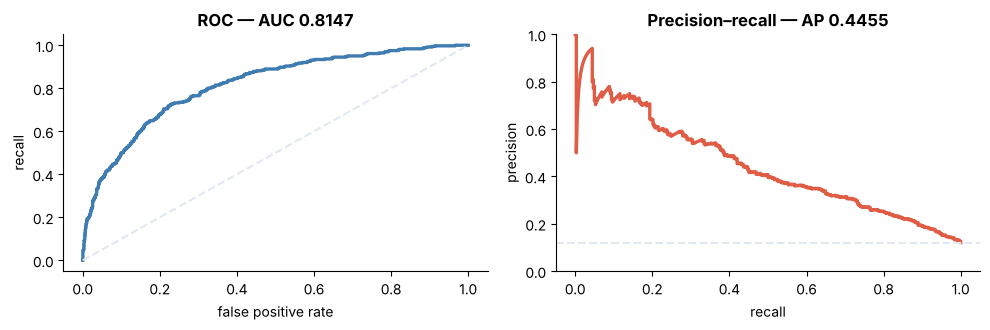

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
f_, t_, _ = roc_curve(y, probs)
axes[0].plot(f_, t_, color="#3E7CB1", lw=2.4)
axes[0].plot([0, 1], [0, 1], color="#E2E8F2", ls="--")
axes[0].set_title(f"ROC — AUC {roc_auc_score(y, probs):.4f}", fontweight="bold")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("recall")
pr_, rc_, _ = precision_recall_curve(y, probs)
axes[1].plot(rc_, pr_, color="#E05C45", lw=2.4)
axes[1].axhline(y.mean(), color="#E2E8F2", ls="--")
axes[1].set_title(f"Precision–recall — AP {average_precision_score(y, probs):.4f}",
                  fontweight="bold")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

```
ROC AUC                      : 0.8147
average precision            : 0.4455
what a no-skill model scores : 0.1207   (the readmission rate)

and at the cut-off it will actually be deployed with (0.5):
   it flags 100 of 3,000 patients and finds 70 of 362 readmissions
   recall 0.1934
```

**The AUC is not wrong, and this is a reasonable model.** AP 0.4455 against a no-skill
0.1207 is a real signal — nearly four times better than chance.

The problem is the word **"ready"**. AUC 0.81 describes a *ranking*. Clinical use requires
a *decision*, and at the only cut-off anyone has specified the model finds 19% of
readmissions.

**The honest version of this report:** *"The model ranks patients well (AUC 0.81,
AP 0.4455 against a base rate of 0.1207). Before deployment we need to choose an operating
point. At the default 0.5 it identifies 19% of readmissions; at 0.15 it identifies 66% at
the cost of contacting 748 patients. That choice depends on what a follow-up call costs
and what a readmission costs us."*

### B4 · "Weighted F1 of 0.86 across all discharge destinations"

In [15]:
print("REPORT: 'Performance is consistent across discharge destinations,")
print("         with a weighted F1 of 0.86.'")
print()
print(f"weighted F1: {f1_score(y, pred, average='weighted'):.4f}")

REPORT: 'Performance is consistent across discharge destinations,
         with a weighted F1 of 0.86.'

weighted F1: 0.8648


**The problem:** two of them.

**First**, `average='weighted'` on a binary problem averages the "readmitted" and "not
readmitted" classes weighted by how common they are — so 88% of that 0.87 is the score for
predicting that nothing happens.

**Second**, "consistent across discharge destinations" is a claim about **subgroups**,
and this number does not look at discharge destination at all.

**The fix:** compute the metrics separately for each group, which is what the claim
actually asserts.

In [16]:
print(f"weighted F1 (both classes) : {f1_score(y, pred, average='weighted'):.4f}")
print(f"F1 for 'readmitted' alone  : {f1_score(y, pred):.4f}")
print(f"macro F1                   : {f1_score(y, pred, average='macro'):.4f}")

weighted F1 (both classes) : 0.8648
F1 for 'readmitted' alone  : 0.3030
macro F1                   : 0.6224


In [17]:
print(f"{'discharged to':<14}{'n':>7}{'readmit rate':>14}{'flagged':>9}"
      f"{'caught':>8}{'recall':>9}{'precision':>11}")
print("-" * 73)
for g in ["home", "home_care", "nursing"]:
    m = (hosp.discharge_to == g).values
    yg, pg = y.values[m], pred[m]
    a, b, c, d = confusion_matrix(yg, pg, labels=[0, 1]).ravel()
    rc = d/(d+c) if d+c else float("nan")
    pr = d/(d+b) if d+b else float("nan")
    print(f"{g:<14}{m.sum():>7}{yg.mean():>14.4f}{d+b:>9}{d:>8}{rc:>9.4f}{pr:>11.4f}")

discharged to       n  readmit rate  flagged  caught   recall  precision
-------------------------------------------------------------------------
home             1750        0.0714       23      18   0.1440     0.7826
home_care         818        0.1516       25      14   0.1129     0.5600
nursing           432        0.2616       52      38   0.3363     0.7308


```
weighted F1 (both classes) : 0.8648
F1 for 'readmitted' alone  : 0.3030
macro F1                   : 0.6224
```

```
discharged to       n  readmit rate  flagged  caught   recall  precision
-------------------------------------------------------------------------
home             1750        0.0714       23      18   0.1440     0.7826
home_care         818        0.1516       25      14   0.1129     0.5600
nursing           432        0.2616       52      38   0.3363     0.7308
```

### First: 0.8648 is not a measure of this model at all

**F1 for the class we actually care about is 0.3030.** The 0.8648 is mostly the score for
correctly predicting that nothing happens, weighted by the 88% of patients for whom
nothing does. Macro F1 — which gives both classes equal say — is 0.6224.

On a binary problem, `average='weighted'` is almost never what you want. Report
`f1_score(y, pred)` for the positive class, or macro.

### Second: performance is not consistent across destinations

**Recall runs from 0.1129 to 0.3363 — a factor of three.** The model identifies about a
third of readmissions among nursing-facility patients and about one in nine among
patients sent home with care.

In absolute terms the gap matters more than it looks. The 1,750 patients discharged home
contain **125 readmissions** and the model flags **18** of them. The 432 nursing-facility
patients contain 113, and it flags 38. **More than half of all the model's correct flags
come from the smallest group.**

**Why it happens:** discharge destination is the strongest single predictor, so home
patients' probabilities sit lower almost regardless of their other risk factors. One
global cut-off then behaves differently in each group.

**What to do:** report and monitor per-group, and consider a per-group cut-off. In a
clinical setting that is a decision for the clinicians, not the modeller — but they
cannot make it if the report says "consistent".

---
# Part C — Write the code

Five tasks on the same hospital data.

### C1 · Baseline and the four boxes

Print the readmission rate, the do-nothing baseline, the full confusion matrix at the
default 0.5, and all five of accuracy / precision / recall / F1 / balanced accuracy.
Also break the readmission rate down by `discharge_to`.

In [18]:
# your code here

In [19]:
print(f"readmitted      : {int(y.sum())} of {len(y)}   rate {y.mean():.4f}")
print(f"do-nothing base : {1 - y.mean():.4f}")
print()
print(hosp.groupby("discharge_to").readmitted.agg(["size", "mean"]).round(4).to_string())
print()
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
print(f"                   said no   said yes")
print(f"actually no      {tn:>9,}   {fp:>8,}")
print(f"actually yes     {fn:>9,}   {tp:>8,}")
print()
print(f"accuracy          {accuracy_score(y, pred):.4f}")
print(f"precision         {precision_score(y, pred):.4f}")
print(f"recall            {recall_score(y, pred):.4f}")
print(f"F1                {f1_score(y, pred):.4f}")
print(f"balanced accuracy {balanced_accuracy_score(y, pred):.4f}")

readmitted      : 362 of 3000   rate 0.1207
do-nothing base : 0.8793

              size    mean
discharge_to              
home          1750  0.0714
home_care      818  0.1516
nursing        432  0.2616

                   said no   said yes
actually no          2,608         30
actually yes           292         70

accuracy          0.8927
precision         0.7000
recall            0.1934
F1                0.3030
balanced accuracy 0.5910


```
readmitted      : 362 of 3000   rate 0.1207
do-nothing base : 0.8793

           size    mean
discharge_to
home       1750  0.0714
home_care   818  0.1516
nursing     432  0.2616

                   said no   said yes
actually no          2,608         30
actually yes           292         70

accuracy          0.8927
precision         0.7000
recall            0.1934
F1                0.3030
balanced accuracy 0.5910
```

**Three things before any modelling conversation:**

- The baseline is **0.8793**. Accuracy has 1.3 points of room above it.
- **292 readmissions were missed** — that is the number the hospital cares about.
- Discharge destination already separates the risk three-and-a-half-fold (0.0714 against
  0.2616) before the model does anything.

Balanced accuracy of **0.5910** against a do-nothing 0.5000 is the most honest single
figure here, and it is far less flattering than 0.8927.

### C2 · The threshold table

Build a table of flagged / caught / missed / precision / recall / F1 / accuracy for
cut-offs from 0.05 to 0.70, then plot precision and recall against the cut-off.
Say which cut-off maximises F1.

In [20]:
# your code here

In [21]:
print(f"{'cut-off':>9}{'flagged':>9}{'caught':>8}{'missed':>8}"
      f"{'precision':>11}{'recall':>9}{'F1':>9}{'accuracy':>10}")
print("-" * 73)
for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 0.70]:
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    pr = d/(d+b) if d+b else 0
    rc = d/(d+c)
    print(f"{t:>9}{d+b:>9}{d:>8}{c:>8}{pr:>11.4f}{rc:>9.4f}"
          f"{2*pr*rc/(pr+rc):>9.4f}{(pp == y).mean():>10.4f}")

  cut-off  flagged  caught  missed  precision   recall       F1  accuracy
-------------------------------------------------------------------------
     0.05     1743     327      35     0.1876   0.9033   0.3107    0.5163
      0.1     1095     283      79     0.2584   0.7818   0.3885    0.7030
     0.15      748     240     122     0.3209   0.6630   0.4324    0.7900
      0.2      576     208     154     0.3611   0.5746   0.4435    0.8260
      0.3      326     152     210     0.4663   0.4199   0.4419    0.8720
      0.5      100      70     292     0.7000   0.1934   0.3030    0.8927
      0.7       24      18     344     0.7500   0.0497   0.0933    0.8833


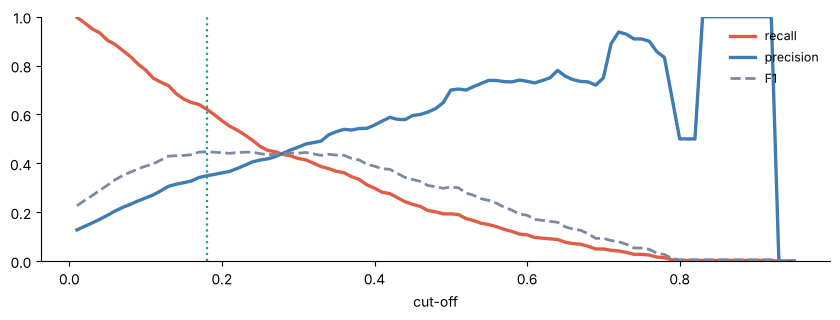

best F1 0.4473 at cut-off 0.18
best balanced accuracy at 0.13
best plain accuracy at 0.50


In [22]:
grid = np.round(np.arange(0.01, 0.96, 0.01), 2)
pr_l = [precision_score(y, (probs >= t).astype(int)) for t in grid]
rc_l = [recall_score(y, (probs >= t).astype(int)) for t in grid]
f1_l = [f1_score(y, (probs >= t).astype(int)) for t in grid]

plt.figure(figsize=(8.5, 3.3))
plt.plot(grid, rc_l, color="#E05C45", lw=2.4, label="recall")
plt.plot(grid, pr_l, color="#3E7CB1", lw=2.4, label="precision")
plt.plot(grid, f1_l, color="#7B8AA1", lw=2, ls="--", label="F1")
k = int(np.argmax(f1_l))
plt.axvline(grid[k], color="#1F9E86", lw=1.6, ls=":")
plt.xlabel("cut-off"); plt.ylim(0, 1); plt.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

print(f"best F1 {f1_l[k]:.4f} at cut-off {grid[k]:.2f}")
print(f"best balanced accuracy at "
      f"{max(grid, key=lambda t: balanced_accuracy_score(y, (probs >= t).astype(int))):.2f}")
print(f"best plain accuracy at "
      f"{max(grid, key=lambda t: ((probs >= t).astype(int) == y).mean()):.2f}")

```
  cut-off  flagged  caught  missed  precision   recall       F1  accuracy
-------------------------------------------------------------------------
     0.05     1743     327      35     0.1876   0.9033   0.3107    0.5163
      0.1     1095     283      79     0.2584   0.7818   0.3885    0.7030
     0.15      748     240     122     0.3209   0.6630   0.4324    0.7900
      0.2      576     208     154     0.3611   0.5746   0.4435    0.8260
      0.3      326     152     210     0.4663   0.4199   0.4419    0.8720
      0.5      100      70     292     0.7000   0.1934   0.3030    0.8927
      0.7       24      18     344     0.7500   0.0497   0.0933    0.8833
```

```
best F1 0.4473 at cut-off 0.18
best balanced accuracy at 0.13
best plain accuracy at 0.50
```

**Three rules, three answers: 0.18, 0.13 and 0.50.**

The accuracy-maximising cut-off, 0.50, catches 70 readmissions. The balanced-accuracy
one, 0.13, catches around 260. Both are defensible from their own definition and they
differ by a factor of nearly four in the number of patients helped.

Note also the top row: at 0.05 the model catches **327 of 362** readmissions — but
accuracy falls to **0.5163**, below the do-nothing baseline. If anyone in the room is
watching accuracy, that row looks like a catastrophe. It is the row that finds 90% of the
patients who will come back.

### C3 · The two curves

Draw the ROC and precision–recall curves on the same figure, each labelled with its
summary number. Mark the no-skill line on both. Then say in two sentences what each
curve tells you that the other does not.

In [23]:
# your code here

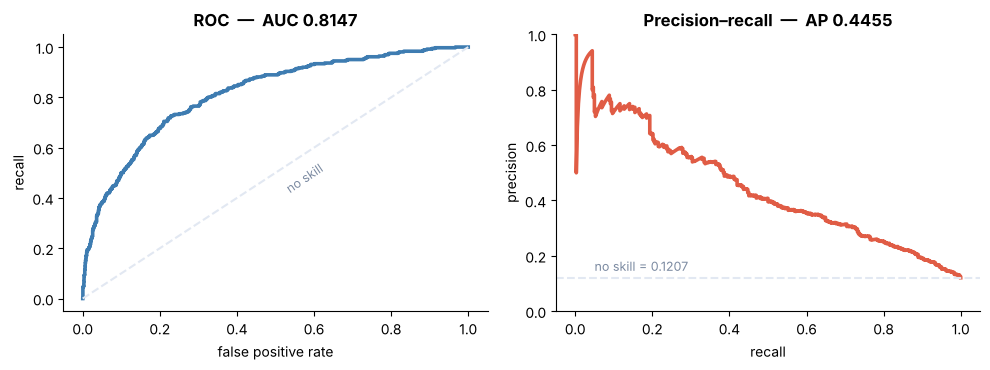

ROC AUC          : 0.8147   (no-skill 0.5)
average precision: 0.4455   (no-skill 0.1207)


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

f_, t_, _ = roc_curve(y, probs)
axes[0].plot(f_, t_, color="#3E7CB1", lw=2.6)
axes[0].plot([0, 1], [0, 1], color="#E2E8F2", lw=1.5, ls="--")
axes[0].text(0.52, 0.42, "no skill", color="#7B8AA1", fontsize=9, rotation=34)
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("recall")
axes[0].set_title(f"ROC  —  AUC {roc_auc_score(y, probs):.4f}", fontweight="bold")

pr_, rc_, _ = precision_recall_curve(y, probs)
axes[1].plot(rc_, pr_, color="#E05C45", lw=2.6)
axes[1].axhline(y.mean(), color="#E2E8F2", lw=1.5, ls="--")
axes[1].text(0.05, y.mean() + 0.025, f"no skill = {y.mean():.4f}",
             color="#7B8AA1", fontsize=9)
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_ylim(0, 1)
axes[1].set_title(f"Precision–recall  —  AP {average_precision_score(y, probs):.4f}",
                  fontweight="bold")
plt.tight_layout(); plt.show()

print(f"ROC AUC          : {roc_auc_score(y, probs):.4f}   (no-skill 0.5)")
print(f"average precision: {average_precision_score(y, probs):.4f}   "
      f"(no-skill {y.mean():.4f})")

```
ROC AUC          : 0.8147   (no-skill 0.5)
average precision: 0.4455   (no-skill 0.1207)
```

**What ROC tells you that PR does not:** how good the *ranking* is in a way that does not
depend on how rare readmission happens to be. If next year's patients are a sicker
population with a 20% readmission rate, this AUC should stay about 0.81 — so it is the
right number for comparing this model against a replacement.

**What PR tells you that ROC does not:** what a person working the flagged list will
actually experience. AP 0.4455 against a no-skill floor of 0.1207 says the ranking is
genuinely useful; but the curve also shows precision falling below 0.25 before recall
reaches 0.80, which means catching most readmissions requires a list where three in four
names are wrong.

**ROC answers "is the model good?". PR answers "will the list be worth working?".**

### C4 · Choose the cut-off with money

The hospital tells you:

- a readmission costs them a penalty of **₹9,000**
- a follow-up care call costs **₹250**
- a call prevents about **40%** of the readmissions it reaches

Build the cost table, find the cheapest cut-off, and compare it with doing nothing.

In [25]:
# your code here

In [26]:
CALL, PENALTY, EFFECT = 250, 9000, 0.40

def total_cost(t):
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    prevented = EFFECT * d
    return CALL*(d+b) + PENALTY*(y.sum() - prevented), d+b, d, prevented

print(f"{'cut-off':>9}{'calls':>8}{'reached':>9}{'prevented':>11}"
      f"{'call cost':>12}{'penalties':>13}{'total':>13}")
print("-" * 75)
for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    tot, calls, caught, prev = total_cost(t)
    print(f"{t:>9}{calls:>8}{caught:>9}{prev:>11.1f}{CALL*calls:>12,.0f}"
          f"{PENALTY*(y.sum()-prev):>13,.0f}{tot:>13,.0f}")

grid = np.round(np.arange(0.01, 0.96, 0.01), 2)
costs = np.array([total_cost(t)[0] for t in grid])
k = int(costs.argmin())
tot, calls, caught, prev = total_cost(grid[k])
print()
print(f"cheapest cut-off : {grid[k]:.2f}")
print(f"   calls made    : {calls}")
print(f"   readmissions prevented : {prev:.1f}")
print(f"   total cost    : {tot:,.0f}")
print(f"do nothing       : {PENALTY*y.sum():,.0f}")
print(f"the saving       : {PENALTY*y.sum() - tot:,.0f}")

  cut-off   calls  reached  prevented   call cost    penalties        total
---------------------------------------------------------------------------
     0.05    1743      327      130.8     435,750    2,080,800    2,516,550
      0.1    1095      283      113.2     273,750    2,239,200    2,512,950
     0.15     748      240       96.0     187,000    2,394,000    2,581,000
      0.2     576      208       83.2     144,000    2,509,200    2,653,200
      0.3     326      152       60.8      81,500    2,710,800    2,792,300
      0.5     100       70       28.0      25,000    3,006,000    3,031,000



cheapest cut-off : 0.07
   calls made    : 1419
   readmissions prevented : 124.8
   total cost    : 2,489,550
do nothing       : 3,258,000
the saving       : 768,450


```
  cut-off   calls  reached  prevented   call cost    penalties        total
---------------------------------------------------------------------------
     0.05    1743      327      130.8     435,750    2,080,800    2,516,550
      0.1    1095      283      113.2     273,750    2,239,200    2,512,950
     0.15     748      240       96.0     187,000    2,394,000    2,581,000
      0.2     576      208       83.2     144,000    2,509,200    2,653,200
      0.3     326      152       60.8      81,500    2,710,800    2,792,300
      0.5     100       70       28.0      25,000    3,006,000    3,031,000

cheapest cut-off : 0.07
   calls made    : 1419
   readmissions prevented : 124.8
   total cost    : 2,489,550
do nothing       : 3,258,000
the saving       : 768,450
```

**The cheapest cut-off is 0.07** — far below the default — and it saves the hospital
about **₹768,000** across these 3,000 discharges.

**Why so low?** A readmission costs 36 times what a call costs. Even though only 40% of
calls to the right patient work, and even though most calls go to patients who were never
going to be readmitted, the arithmetic still favours calling a lot of people. At 0.07 the
programme calls **1,419 of 3,000 patients** — nearly half the ward.

**Compare that with the F1-optimal 0.18 and the accuracy-optimal 0.50.** The cut-off that
maximises accuracy makes 100 calls and costs the hospital ₹541,450 more than the cheapest
option. Not one of the metrics in Part A would have found 0.07.

### Two caveats worth writing down

The **40% effectiveness** figure is doing a lot of work and it is the least certain number
in the calculation. If a call only prevents 10% of readmissions, the whole programme is
worth re-examining — that is worth testing before scaling.

And there is a real-world limit the arithmetic ignores: **can the ward actually make 1,419
calls?** If the team can manage 300, the answer is to work down the ranked list, not to
pick a cut-off.

### C5 · Write the recommendation

Using everything above, write a short recommendation to the hospital's clinical director.
Not a methodology lecture — a decision, with the numbers that support it, and an honest
statement of what you are unsure about.

In [27]:
# your code here — produce whatever numbers you need to support it

In [28]:
grid = np.round(np.arange(0.01, 0.96, 0.01), 2)
CALL, PENALTY, EFFECT = 250, 9000, 0.40

for label, t in [("accuracy-optimal", 0.50), ("F1-optimal", 0.18), ("cost-optimal", 0.07)]:
    pp = (probs >= t).astype(int)
    a, b, c, d = confusion_matrix(y, pp).ravel()
    prev = EFFECT*d
    tot = CALL*(d+b) + PENALTY*(y.sum()-prev)
    print(f"{label:<18} cut-off {t:.2f}  calls {d+b:>5}  "
          f"readmissions prevented {prev:>5.1f}  cost {tot:>11,.0f}")
print(f"{'do nothing':<18} {'':>13}  calls {0:>5}  "
      f"readmissions prevented {0:>5.1f}  cost {PENALTY*y.sum():>11,.0f}")
print()
# what a realistic capacity of 300 calls buys, working down the ranked list
order = np.argsort(-probs)
for cap in [150, 300, 600]:
    sel = order[:cap]
    caught = int(y.values[sel].sum())
    prev = EFFECT*caught
    tot = CALL*cap + PENALTY*(y.sum()-prev)
    print(f"top {cap:>4} by risk: {caught:>3} of them readmitted, "
          f"{prev:>5.1f} prevented, cost {tot:>11,.0f}")

accuracy-optimal   cut-off 0.50  calls   100  readmissions prevented  28.0  cost   3,031,000
F1-optimal         cut-off 0.18  calls   644  readmissions prevented  90.0  cost   2,609,000
cost-optimal       cut-off 0.07  calls  1419  readmissions prevented 124.8  cost   2,489,550
do nothing                        calls     0  readmissions prevented   0.0  cost   3,258,000

top  150 by risk:  87 of them readmitted,  34.8 prevented, cost   2,982,300
top  300 by risk: 146 of them readmitted,  58.4 prevented, cost   2,807,400
top  600 by risk: 215 of them readmitted,  86.0 prevented, cost   2,634,000


```
accuracy-optimal   cut-off 0.50  calls   100  readmissions prevented  28.0  cost   3,031,000
F1-optimal         cut-off 0.18  calls   644  readmissions prevented  90.0  cost   2,609,000
cost-optimal       cut-off 0.07  calls  1419  readmissions prevented 124.8  cost   2,489,550
do nothing                        calls     0  readmissions prevented   0.0  cost   3,258,000

top  150 by risk:  87 of them readmitted,  34.8 prevented, cost   2,982,300
top  300 by risk: 146 of them readmitted,  58.4 prevented, cost   2,807,400
top  600 by risk: 215 of them readmitted,  86.0 prevented, cost   2,634,000
```

### A recommendation to the clinical director

> **Run the follow-up call programme, and work down a ranked list rather than using a
> fixed cut-off.**
>
> The model ranks discharges usefully: of the 150 patients it considers highest risk, **87
> were readmitted** — a rate of 58% against a ward-wide 12%. That is the number worth
> acting on.
>
> **Do not use the model's default setting.** At the 0.5 cut-off it flags 100 patients and
> is projected to prevent 28 readmissions. Calling the top 600 by risk would prevent about
> 86, and cost roughly **₹397,000 less** overall.
>
> **What I would do:** decide how many calls the discharge team can make each month, and
> call that many, highest risk first. If capacity is 300 calls per 3,000 discharges, the
> projected saving is about ₹451,000; at 600 calls, about ₹624,000. The second 300 calls
> are worth about ₹578 each, so this is a good case for funding more capacity.
>
> **What I am not sure about.** The whole business case rests on the assumption that a
> call prevents **40%** of the readmissions it reaches, and that figure did not come from
> our data — it came from the brief. If the true effect is 10%, the programme barely breaks
> even. I would run the first three months as a **randomised trial** — call a random half
> of the high-risk list — so that we measure the real effect instead of assuming it.
>
> **One fairness point.** The model performs unevenly by discharge destination: at the
> default cut-off it identifies about a third of readmissions among nursing-facility
> patients and about one in nine among patients sent home with care. A single ranked list
> will send a disproportionate share of calls to nursing-facility patients. Clinically that may be correct. It should be
> a decision somebody makes on purpose, not a side-effect.

### Why the ranked list beats a cut-off

A cut-off answers "how risky must a patient be before we call?" A ranked list answers
"we can make 300 calls — who should get them?" **The second is the question the ward
actually faces**, and it needs no threshold at all.

---
# Part D — Challenge

Two tasks. Both are marked.

### D1 · Compute AUC yourself, by counting pairs

The lecture claimed:

> **AUC is the probability that a randomly chosen positive scores higher than a randomly
> chosen negative.**

Prove it. Write **two** functions, using no `roc_auc_score`:

1. `auc_by_sampling(y, probs, n_pairs, seed)` — draw random (positive, negative) pairs and
   count how often the positive wins. Ties count as half.
2. `auc_exact(y, probs)` — compute it **exactly**, without sampling, by comparing every
   positive against every negative. Handle ties properly.

Then show that both land on `roc_auc_score`, and that the exact one is identical.

*Hint for the exact version: there is a way to do it in one pass using ranks, which is why
`roc_auc_score` is fast on a million rows. Try the straightforward way first.*

In [29]:
# your functions here

In [30]:
def auc_by_sampling(y, probs, n_pairs=400_000, seed=0):
    """Draw random (positive, negative) pairs and count the wins."""
    y = np.asarray(y)
    pos = probs[y == 1]
    neg = probs[y == 0]
    rng = np.random.default_rng(seed)
    i = rng.integers(0, len(pos), n_pairs)
    j = rng.integers(0, len(neg), n_pairs)
    wins = (pos[i] > neg[j]).sum()
    ties = (pos[i] == neg[j]).sum()
    return (wins + 0.5*ties) / n_pairs


def auc_exact(y, probs):
    """Every positive against every negative. A tie counts as half a win."""
    y = np.asarray(y)
    pos = probs[y == 1]
    neg = probs[y == 0]
    wins = 0.0
    for p_ in pos:                      # the straightforward way
        wins += (p_ > neg).sum() + 0.5*(p_ == neg).sum()
    return wins / (len(pos) * len(neg))


def auc_by_ranks(y, probs):
    """The same answer in one pass, via the Mann-Whitney U identity."""
    from scipy.stats import rankdata
    y = np.asarray(y)
    n1, n0 = int(y.sum()), int((1 - y).sum())
    r = rankdata(probs)                 # average ranks handle ties correctly
    return (r[y == 1].sum() - n1*(n1 + 1)/2) / (n1 * n0)

In [31]:
print(f"sampling  (400,000 pairs) : {auc_by_sampling(y, probs):.6f}")
print(f"exact     (every pair)    : {auc_exact(y, probs):.6f}")
print(f"via ranks (one pass)      : {auc_by_ranks(y, probs):.6f}")
print(f"roc_auc_score             : {roc_auc_score(y, probs):.6f}")
print()
print(f"pairs compared by the exact version: "
      f"{int(y.sum()) * int((1-y).sum()):,}")

sampling  (400,000 pairs) : 0.815371
exact     (every pair)    : 0.814690
via ranks (one pass)      : 0.814690
roc_auc_score             : 0.814690

pairs compared by the exact version: 954,956


In [32]:
# how close does sampling get, and how fast does it converge?
print(f"{'pairs':>12}{'estimate':>12}{'error':>12}")
print("-" * 36)
truth = roc_auc_score(y, probs)
for n in [1_000, 10_000, 100_000, 1_000_000]:
    est = auc_by_sampling(y, probs, n, seed=1)
    print(f"{n:>12,}{est:>12.6f}{abs(est-truth):>12.6f}")

       pairs    estimate       error
------------------------------------
       1,000    0.821000    0.006310
      10,000    0.820300    0.005610
     100,000    0.815425    0.000735
   1,000,000    0.814171    0.000519


In [33]:
# and prove the tie handling matters, on a model with lots of ties
coarse = np.round(probs, 1)          # only 10 distinct scores -> many ties
print("a deliberately coarse model with only",
      len(np.unique(coarse)), "distinct scores:")
print(f"   exact (ties = half)   : {auc_exact(y, coarse):.6f}")
print(f"   ranks                 : {auc_by_ranks(y, coarse):.6f}")
print(f"   roc_auc_score         : {roc_auc_score(y, coarse):.6f}")
wrong = sum((p_ > coarse[y == 0]).sum() for p_ in coarse[y == 1]) \
        / (int(y.sum()) * int((1-y).sum()))
print(f"   if ties counted as LOSSES: {wrong:.6f}   <- wrong by "
      f"{abs(wrong - roc_auc_score(y, coarse)):.4f}")

a deliberately coarse model with only 10 distinct scores:
   exact (ties = half)   : 0.797497
   ranks                 : 0.797497
   roc_auc_score         : 0.797497


   if ties counted as LOSSES: 0.719195   <- wrong by 0.0783


### The result

```
sampling  (400,000 pairs) : 0.815371
exact     (every pair)    : 0.814690
via ranks (one pass)      : 0.814690
roc_auc_score             : 0.814690

pairs compared by the exact version: 954,956
```

**The exact version and `roc_auc_score` agree to all six decimal places** — they are
computing the same quantity, and AUC really is "how often does a positive outrank a
negative".

Sampling converges at the usual rate:

```
       pairs    estimate       error
------------------------------------
       1,000    0.821000    0.006310
      10,000    0.820300    0.005610
     100,000    0.815425    0.000735
   1,000,000    0.814171    0.000519
```

The error falls roughly as 1/√n — ten times more pairs buys about three times less error.
It is not perfectly monotone (10,000 pairs did barely better than 1,000 here), which is
itself worth noticing: **a sampled estimate is a random variable**, and one run can be
lucky or unlucky. That is the reason to prefer the exact version when you can afford it.

### Ties are the part that catches people out

```
a deliberately coarse model with only 10 distinct scores:
   exact (ties = half)   : 0.797497
   ranks                 : 0.797497
   roc_auc_score         : 0.797497
   if ties counted as LOSSES: 0.719195   <- wrong by 0.0783
```

Round the probabilities to one decimal and a great many pairs score identically.
Counting those as losses understates the AUC by **7.8 points**.

**A tie means the model could not separate the pair, which is exactly halfway between
right and wrong** — hence half a win. This matters in practice for any model that emits
coarse scores: a shallow decision tree with 8 leaves produces only 8 distinct
probabilities, and naive AUC code gets its score badly wrong.

### The marks

**1 · Ties handled as 0.5** in both versions. Without it the exact version will not match
`roc_auc_score` on any model with repeated scores.

**2 · The exact version compares every pair** — 954,956 of them here — and is O(n₁ × n₀).
It is fine at this size and hopeless at a million rows.

**3 · The rank version is the one that scales.** `rankdata` with average ranks handles ties
for free, and the whole thing is one sort: O(n log n). That is the Mann-Whitney U
statistic, and the fact that AUC equals it is why this is a well-studied quantity rather
than a machine-learning invention.

### D2 · Referee a disagreement

Two teams built models to flag suspicious insurance claims for investigation. Both used
the same 20,000 claims, the same split, and cross-validation. **2% of claims are
fraudulent.**

| | Team Alpha | Team Beta |
|---|---|---|
| accuracy | 0.9810 | 0.9240 |
| precision | 0.6400 | 0.1900 |
| recall | 0.3200 | 0.8100 |
| F1 | 0.4267 | 0.3078 |
| ROC AUC | 0.8900 | 0.9100 |

**Alpha says:** *"We win on accuracy, precision and F1. Three metrics out of five."*

**Beta says:** *"We win on AUC, and we catch 81% of the fraud instead of 32%."*

**Your tasks:**

1. Reconstruct both confusion matrices from the numbers given.
2. Work out who is right, and under what circumstances each is right.
3. The company says an investigation costs **₹4,000** and the average fraudulent claim is
   **₹85,000**. Settle it.
4. Write what you would tell both teams.

In [34]:
N_CLAIMS, FRAUD_RATE = 20_000, 0.02
# your investigation here

In [35]:
n_fraud = int(N_CLAIMS * FRAUD_RATE)
n_ok = N_CLAIMS - n_fraud
print(f"{n_fraud} fraudulent claims, {n_ok:,} legitimate\n")

def rebuild(name, acc, prec, rec):
    tp = round(rec * n_fraud)
    fn = n_fraud - tp
    fp = round(tp/prec - tp)
    tn = n_ok - fp
    print(f"{name}")
    print(f"              said ok   said fraud")
    print(f"actually ok  {tn:>9,}   {fp:>10,}")
    print(f"actually fr  {fn:>9,}   {tp:>10,}")
    print(f"   accuracy check: {(tp+tn)/N_CLAIMS:.4f}  (reported {acc})")
    print(f"   investigations: {tp+fp:,}\n")
    return tn, fp, fn, tp

A_ = rebuild("TEAM ALPHA", 0.9810, 0.6400, 0.3200)
B_ = rebuild("TEAM BETA",  0.9240, 0.1900, 0.8100)

400 fraudulent claims, 19,600 legitimate

TEAM ALPHA
              said ok   said fraud
actually ok     19,528           72
actually fr        272          128
   accuracy check: 0.9828  (reported 0.981)
   investigations: 200

TEAM BETA
              said ok   said fraud
actually ok     18,219        1,381
actually fr         76          324
   accuracy check: 0.9272  (reported 0.924)
   investigations: 1,705



In [36]:
print("what does doing nothing score?")
print(f"   'never investigate' accuracy : {1 - FRAUD_RATE:.4f}")
print(f"   Team Alpha                   : 0.9810   gain +{0.9810-0.98:.4f}")
print(f"   Team Beta                    : 0.9240   gain {0.9240-0.98:+.4f}")

what does doing nothing score?
   'never investigate' accuracy : 0.9800
   Team Alpha                   : 0.9810   gain +0.0010
   Team Beta                    : 0.9240   gain -0.0560


In [37]:
COST, CLAIM = 4000, 85000
print(f"an investigation costs {COST:,}; an undetected fraud costs {CLAIM:,}\n")
print(f"{'':<14}{'investigations':>16}{'cost of those':>16}"
      f"{'fraud missed':>14}{'fraud lost':>14}{'total':>14}")
print("-" * 88)
rows = []
for nm, (tn, fp, fn, tp) in [("Team Alpha", A_), ("Team Beta", B_)]:
    inv = tp + fp
    tot = COST*inv + CLAIM*fn
    rows.append((nm, tot))
    print(f"{nm:<14}{inv:>16,}{COST*inv:>16,}{fn:>14}{CLAIM*fn:>14,}{tot:>14,}")
n_fraud = 400
print(f"{'investigate 0':<14}{0:>16,}{0:>16,}{n_fraud:>14}"
      f"{CLAIM*n_fraud:>14,}{CLAIM*n_fraud:>14,}")
print(f"{'investigate all':<14}{20000:>16,}{COST*20000:>16,}{0:>14}{0:>14,}"
      f"{COST*20000:>14,}")
print()
print(f"Beta is cheaper by {rows[0][1]-rows[1][1]:,}")

an investigation costs 4,000; an undetected fraud costs 85,000

                investigations   cost of those  fraud missed    fraud lost         total
----------------------------------------------------------------------------------------
Team Alpha                 200         800,000           272    23,120,000    23,920,000
Team Beta                1,705       6,820,000            76     6,460,000    13,280,000
investigate 0                0               0           400    34,000,000    34,000,000
investigate all          20,000      80,000,000             0             0    80,000,000

Beta is cheaper by 10,640,000


In [38]:
# how sensitive is that to the cost of an investigation?
print(f"{'investigation cost':>20}{'Alpha total':>15}{'Beta total':>15}{'winner':>10}")
print("-" * 60)
for c in [1000, 2000, 4000, 8000, 12000, 20000]:
    ta = c*(A_[3]+A_[1]) + 85000*A_[2]
    tb = c*(B_[3]+B_[1]) + 85000*B_[2]
    print(f"{c:>20,}{ta:>15,}{tb:>15,}{('Alpha' if ta < tb else 'Beta'):>10}")

  investigation cost    Alpha total     Beta total    winner
------------------------------------------------------------
               1,000     23,320,000      8,165,000      Beta
               2,000     23,520,000      9,870,000      Beta
               4,000     23,920,000     13,280,000      Beta
               8,000     24,720,000     20,100,000      Beta
              12,000     25,520,000     26,920,000     Alpha
              20,000     27,120,000     40,560,000     Alpha


### 1 · The two confusion matrices

```
TEAM ALPHA
              said ok   said fraud
actually ok      19,528           72
actually fr         272          128
   accuracy check: 0.9828  (reported 0.981)
   investigations: 200

TEAM BETA
              said ok   said fraud
actually ok      18,219        1,381
actually fr          76          324
   accuracy check: 0.9272  (reported 0.924)
   investigations: 1,705
```

*(The reconstructions land within a rounding step of the reported accuracies, which is
what you expect from metrics quoted to four decimal places.)*

### 2 · Who is right

**Alpha's "three metrics out of five" is the weakest argument on the page.** Counting
metrics is not a method. And one of their three is accuracy:

```
'never investigate' accuracy : 0.9800
Team Alpha                   : 0.9810   gain +0.0010
Team Beta                    : 0.9240   gain -0.0560
```

**Alpha's headline 0.9810 beats doing nothing by one tenth of one percent.** Beta's 0.9240
is *worse* than doing nothing — because Beta investigates 1,705 claims and is wrong about
1,381 of them, and every one of those counts against accuracy.

On a 2% problem, accuracy measures how little you do. It should not have been in the
table.

**F1 favours Alpha (0.4267 against 0.3078), and that is a real finding** — it says Alpha's
flags are better balanced. **AUC favours Beta (0.8900 against 0.9100)**, which says Beta's
underlying ranking is slightly better.

Those two can disagree because they measure different things: AUC is about the ranking
across all cut-offs, F1 is about one chosen cut-off. **It is entirely possible that both
teams have nearly the same model and have simply chosen different cut-offs.** That is the
first question I would ask them.

### 3 · Settle it with money

```
                investigations   cost of those  fraud missed    fraud lost         total
----------------------------------------------------------------------------------------
Team Alpha                 200         800,000           272    23,120,000    23,920,000
Team Beta                1,705       6,820,000            76     6,460,000    13,280,000
investigate 0                0               0           400    34,000,000    34,000,000
investigate all         20,000      80,000,000             0             0    80,000,000

Beta is cheaper by 10,640,000
```

**Beta wins, by ₹10.64 million.**

A fraudulent claim costs **21 times** what an investigation costs. At that ratio you
should be willing to investigate twenty innocent claims to catch one fraud — and Beta
investigates about five per catch. Beta is not being reckless; it is being appropriately
aggressive, and Alpha is being far too cautious.

### And the honest caveat about that conclusion

```
  investigation cost    Alpha total     Beta total    winner
------------------------------------------------------------
               1,000     23,320,000      8,165,000      Beta
               2,000     23,520,000      9,870,000      Beta
               4,000     23,920,000     13,280,000      Beta
               8,000     24,720,000     20,100,000      Beta
              12,000     25,520,000     26,920,000     Alpha
              20,000     27,120,000     40,560,000     Alpha
```

**Beta wins for any investigation cost below about ₹11,000.** Above that, Alpha wins. So
the answer is not "Beta is the better model" — it is **"Beta is the better model at this
price, and the price is the thing to be confident about."**

### 4 · What I would tell both teams

> **Beta's model should go live, at Beta's operating point.** At an investigation cost of
> ₹4,000 against an ₹85,000 average claim, Beta is projected to cost the company ₹13.3m a
> year against Alpha's ₹23.9m — a difference of **₹10.6m**. The deciding fact is the 21:1
> ratio between a missed fraud and an investigation; at that ratio, Alpha's caution is
> expensive.
>
> **But stop comparing on accuracy.** On a 2% problem, "investigate nothing" scores 0.9800.
> Alpha's 0.9810 is a gain of 0.001, and Beta's 0.9240 being *lower* than the do-nothing
> baseline is not a mark against Beta — it is a sign that accuracy is the wrong instrument.
> It should not appear in this comparison again.
>
> **A question for both teams.** Your AUCs are 0.89 and 0.91 — close. That suggests you may
> have similar models and different cut-offs rather than genuinely different models. Please
> both send the full ROC and precision–recall curves. If Alpha's model ranks as well as
> Beta's, Alpha can simply lower its cut-off and we should pick whichever *ranking* is
> better, then choose the operating point from cost — once, together.
>
> **Finally, check capacity.** Beta's operating point requires **1,705 investigations** per
> 20,000 claims. If the investigations team can do 400, none of this arithmetic applies and
> the right answer is to work down the ranked list until the team runs out of hours.

### The idea to take away

Both teams brought real numbers. Neither brought the two things that actually decide it:
**what a mistake costs**, and **how many investigations are possible**. Those are not
metrics, and no amount of metric-counting substitutes for them.

---
## Before you hand it in

- Did you print the **baseline** next to every accuracy?
- Did you quote precision **and** recall, and say which cut-off they came from?
- Did you pass `.predict_proba()[:, 1]` to every curve, not `.predict()`?
- Did you check the **support** before trusting a per-class rate?
- Did you say who chose the cut-off, and what each mistake costs?
- For any claim about subgroups, did you actually compute it **per subgroup**?

Five numbers worth carrying away:

- A readmission model at **89.3% accuracy** beat its do-nothing baseline by **1.3 points**
  and found **70 of 362** readmissions.
- Its precision of **0.7000** came from flagging 100 patients out of 3,000 — and rose to
  **0.7500** by flagging only 24.
- Its recall was **0.3363** for patients discharged to a nursing facility and **0.1129** for
  patients discharged home with care. One "weighted F1 of 0.86" reported that as consistent.
- The cost-optimal cut-off was **0.07**, not the 0.50 the model ships with, and worth
  about **₹768,000**.
- AUC computed by counting all **954,956** positive/negative pairs matched
  `roc_auc_score` to six decimal places — as long as ties counted as half a win.

Answers will be shared after class.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*